# Model risk

The same product priced with one volatility per underlying and with the local volatility of the whole smile. The closed forms of path-dependent barriers use one volatility too.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
BLUE, GREEN, RED, ORANGE, GREY = "#1f4e79", "#1a9850", "#d73027", "#f46d43", "#7f7f7f"
FIGURES = "../docs/figures"

     Smile (exact):  89.575 ± 0.000  (gap to exact +0.00)
  One vol: barrier:  84.618 ± 0.037  (gap to exact -4.96)
      One vol: ATM:  89.652 ± 0.033  (gap to exact +0.08)
      Local vol MC:  89.557 ± 0.045  (gap to exact -0.02)


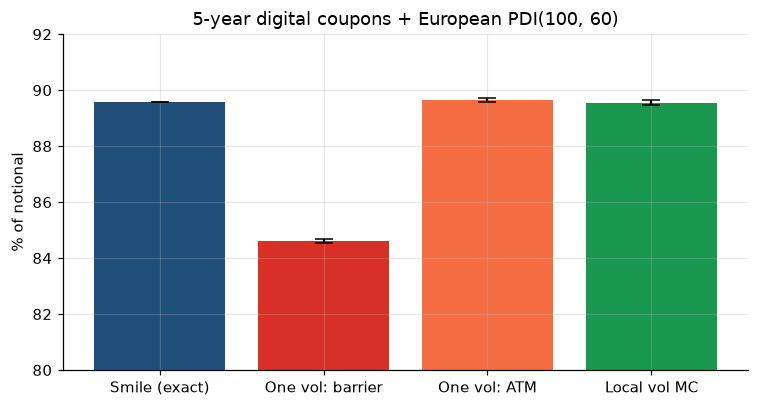

In [2]:
from spricer.bricks import BarrierOption, DigitalOption, ZeroCoupon
from spricer.market import FlatVol, Market
from spricer.market.defaults import default_market
from spricer.mc import price_note
from spricer.monitoring import Monitoring
from spricer.products.capital_protection import find_note
from spricer.products.notes import Note, NoteLeg

market = default_market()
years = [1.0, 2.0, 3.0, 4.0, 5.0]
legs = [NoteLeg(f"Coupon {t:g}y", DigitalOption("call", 100.0, t), 5.0) for t in years]
legs += [
    NoteLeg("Redemption", ZeroCoupon(5.0), 100.0),
    NoteLeg("Protection", BarrierOption("put", "down-and-in", 100.0, 60.0, 5.0), -1.0),
]
strip = Note("Coupon strip", 5.0, 100.0, tuple(legs), formula=lambda p: p)
exact = float(strip.value(market))
results = {"Smile (exact)": (exact, 0.0)}
for label, vol in (
    ("One vol: barrier", market.vol.vol(60.0, 5.0)),
    ("One vol: ATM", market.vol.vol(100.0, 5.0)),
):
    one = Market(100.0, market.rate, market.dividend_yield, FlatVol(float(vol)))
    mc = price_note(strip, one, n_paths=200_000, seed=6).total
    results[label] = (mc.value, mc.std_error)
local = price_note(strip, market, n_paths=200_000, seed=6).total
results["Local vol MC"] = (local.value, local.std_error)
for name, (v, e) in results.items():
    print(f"{name:>18}: {v:7.3f} ± {e:.3f}  (gap to exact {v - exact:+.2f})")
fig, ax = plt.subplots(figsize=(7, 3.8))
names = list(results)
ax.bar(
    names,
    [results[n][0] for n in names],
    yerr=[2 * results[n][1] for n in names],
    color=[BLUE, RED, ORANGE, GREEN],
    capsize=6,
)
ax.set_ylim(80, 92)
ax.set(title="5-year digital coupons + European PDI(100, 60)", ylabel="% of notional")
fig.tight_layout()
fig.savefig(f"{FIGURES}/model_risk_strip.png")

## Continuous barriers: one volatility against the smile

In [3]:
spec = find_note("Shark note (up)")
for name in ("Shark note (up)", "Shark note (down)"):
    note = find_note(name).build({}, 3.0, 100.0, Monitoring.CONTINUOUS)
    closed = float(note.value(market))
    mc = price_note(note, market, n_paths=100_000, seed=3).total
    print(
        f"{name}: closed form (one vol) {closed:.2f}, local vol MC {mc.value:.2f} ± "
        f"{mc.std_error:.2f} -> gap {mc.value - closed:+.2f} points"
    )

Shark note (up): closed form (one vol) 94.02, local vol MC 95.05 ± 0.01 -> gap +1.02 points


Shark note (down): closed form (one vol) 95.87, local vol MC 94.31 ± 0.01 -> gap -1.56 points
